# ES + GEX/DEX de SPX (proxy)

El gráfico alinea strikes SPX con niveles ES usando un desplazamiento medido entre referencias simultáneas. Verde = exposición positiva; rojo = negativa bajo **calls cortas / puts largas**. Los datos de esta demo son totalmente sintéticos. El DEX de este escenario tiende a ser negativo por la propia convención de signos. Edita la configuración y ejecuta todo para regenerar las imágenes.

In [1]:
# Archivos de una misma captura. El ejemplo incluido es enteramente SINTÉTICO.
CARPETA = "ejemplos/estudio_es_spx_demo"
GRAFICOS = ["GEX", "DEX"]  # Puedes mostrar uno o los dos.

FILTROS = {
    "vencimientos": [],      # [] = todos
    "rango_puntos_es": 45,  # niveles ES dentro de +/- este rango del último cierre
    "max_niveles": 12,
    "min_abs_millones": 0,
}

ESTILO = {
    "tema": "default",     # "dark_background"
    "figsize": (15, 8),
    "dpi": 150,
    "fuente": "DejaVu Sans",
    "tamano_fuente": 10,
    "verde": "#1c9b72",  # exposición positiva
    "rojo": "#cf5361",   # exposición negativa
    "velas_alcistas": "#278da8",
    "velas_bajistas": "#d08b3c",
    "referencia": "#8054ba",
    "cuadricula": True,
    "leyenda": True,
    "lineas_niveles": True,
    "etiquetas_niveles": True,
    "opacidad": 0.82,
    "ancho_vela": 0.6,
    "grosor_mecha": 1.2,
    "ancho_barra_es": 3.5,
    "titulos": {},      # ejemplo: {"GEX": "Mi estudio GEX"}
    "limites_y": None,  # ejemplo: (4980, 5040)
}

EXPORTACION = {
    "activar": False,
    "carpeta": "resultados/visualizaciones/es_spx",
    "formatos": ["png"],  # también "svg" y "pdf"
    "sobrescribir": False,
}


In [2]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown
from options_flow.estudios_es import calcular_estudio

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLAN_REDISENO.md").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abre este notebook dentro del proyecto kronos")
carpeta = Path(CARPETA)
carpeta = carpeta if carpeta.is_absolute() else RAIZ / carpeta
meta_path, opciones_path, precio_path = [carpeta / n for n in
    ("metadatos.json", "opciones_spx.csv", "precio_es.csv")]
meta = json.loads(meta_path.read_text(encoding="utf-8"))
if meta["subyacente_precio"] != "ES" or meta["subyacente_opciones"] != "SPX":
    raise ValueError("Se requieren precios ES y opciones SPX, identificados por separado")
if meta["estado_datos"] not in {"SINTETICO", "REAL"}:
    raise ValueError("estado_datos debe ser SINTETICO o REAL")
if meta["convencion"] != "HIPOTESIS_DEALER_CALLS_CORTAS_PUTS_LARGAS":
    raise ValueError("Convención dealer no soportada")
if abs(pd.Timestamp(meta["opciones_observadas_utc"]) - pd.Timestamp(meta["spx_hora_utc"])) > pd.Timedelta(minutes=5):
    raise ValueError("Greeks SPX y referencia SPX no están sincronizados")
opciones = pd.read_csv(opciones_path)
precio = pd.read_csv(precio_path)
precio["hora_utc"] = pd.to_datetime(precio["hora_utc"], utc=True)
precio = precio.sort_values("hora_utc")
for columna in ("open", "high", "low", "close"):
    precio[columna] = pd.to_numeric(precio[columna], errors="raise")
if precio.empty or not ((precio["high"] >= precio[["open", "close", "low"]].max(axis=1)) &
                         (precio["low"] <= precio[["open", "close", "high"]].min(axis=1))).all():
    raise ValueError("Barras ES inválidas")
if FILTROS["vencimientos"]:
    opciones = opciones[opciones["vencimiento"].isin(FILTROS["vencimientos"])]
niveles = pd.DataFrame(calcular_estudio(
    opciones.to_dict("records"),
    spx_referencia=float(meta["spx_referencia"]),
    es_referencia=float(meta["es_referencia"]),
    spx_hora_utc=meta["spx_hora_utc"], es_hora_utc=meta["es_hora_utc"],
))
ultimo_es = float(precio.iloc[-1]["close"])
niveles = niveles[abs(niveles["nivel_es_proxy"] - ultimo_es) <= FILTROS["rango_puntos_es"]]
if FILTROS["max_niveles"] and len(niveles) > FILTROS["max_niveles"]:
    niveles = (niveles.assign(distancia=(niveles["nivel_es_proxy"]-ultimo_es).abs())
               .nsmallest(FILTROS["max_niveles"], "distancia").drop(columns="distancia")
               .sort_values("nivel_es_proxy"))
if niveles.empty:
    raise ValueError("No quedan niveles con estos filtros")
plt.style.use(ESTILO["tema"])
plt.rcParams.update({"font.family": ESTILO["fuente"], "font.size": ESTILO["tamano_fuente"]})
huella = hashlib.sha256(meta_path.read_bytes() + opciones_path.read_bytes() + precio_path.read_bytes()).hexdigest()
display(Markdown(
    f"**{meta['estado_datos']}** · ES precio / SPX opciones · {meta['fuente']}  \n"
    f"**Referencia SPX:** {meta['spx_referencia']} ({meta['spx_hora_utc']}) · "
    f"**ES:** {meta['es_referencia']} ({meta['es_hora_utc']})  \n"
    f"**SHA-256 conjunto de entradas:** `{huella}`  \n"
    "Barras = escenario dealer de calls cortas y puts largas sobre OI; no son posiciones observadas."
))


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7812\1543050098.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  if abs(pd.Timestamp(meta["opciones_observadas_utc"]) - pd.Timestamp(meta["spx_hora_utc"])) > pd.Timedelta(minutes=5):


**SINTETICO** · ES precio / SPX opciones · GENERADO_PARA_PRUEBA  
**Referencia SPX:** 5000.0 (2026-11-16T20:00:00+00:00) · **ES:** 5012.0 (2026-11-16T20:00:00+00:00)  
**SHA-256 conjunto de entradas:** `b28d0841cc847b2c5c214236828f966022f6184db6863ac154c829650da3c0b1`  
Barras = escenario dealer de calls cortas y puts largas sobre OI; no son posiciones observadas.

In [3]:
def dibujar_estudio(clave):
    campo = "gex_usd_por_1pct" if clave == "GEX" else "dex_usd"
    unidad = "millones USD / 1% de SPX" if clave == "GEX" else "millones USD nocionales"
    datos = niveles.copy()
    datos["millones"] = datos[campo] / 1_000_000
    datos = datos[abs(datos["millones"]) >= FILTROS["min_abs_millones"]]
    if datos.empty:
        print(f"Sin niveles {clave} con estos filtros")
        return
    fig, (ax, barras) = plt.subplots(1, 2, sharey=True, figsize=ESTILO["figsize"], dpi=ESTILO["dpi"],
                                     gridspec_kw={"width_ratios": [3.7, 1.2], "wspace": 0.04})
    for i, fila in enumerate(precio.itertuples()):
        color = ESTILO["velas_alcistas"] if fila.close >= fila.open else ESTILO["velas_bajistas"]
        ax.vlines(i, fila.low, fila.high, color=color, linewidth=ESTILO["grosor_mecha"])
        cuerpo = max(abs(fila.close - fila.open), 0.15)
        ax.add_patch(Rectangle((i - ESTILO["ancho_vela"]/2, min(fila.open, fila.close)),
                               ESTILO["ancho_vela"], cuerpo, color=color, alpha=ESTILO["opacidad"]))
    ax.axhline(ultimo_es, color=ESTILO["referencia"], ls="--", lw=1.2, label="Último cierre ES")
    ax.set_xlim(-1, len(precio))
    if ESTILO["limites_y"] is not None:
        ax.set_ylim(*ESTILO["limites_y"])
    else:
        centro = ultimo_es
        ax.set_ylim(centro - FILTROS["rango_puntos_es"], centro + FILTROS["rango_puntos_es"])
    pasos = max(1, len(precio) // 6)
    etiquetas = precio["hora_utc"].dt.strftime("%H:%M UTC")
    ax.set_xticks(range(0, len(precio), pasos), etiquetas.iloc[::pasos], rotation=30)
    ax.set_xlabel("Hora de barras ES")
    ax.set_ylabel("Nivel ES")
    if ESTILO["cuadricula"]:
        ax.grid(True, alpha=0.2)
    if ESTILO["leyenda"]:
        ax.legend(loc="upper left")

    colores = [ESTILO["verde"] if v >= 0 else ESTILO["rojo"] for v in datos["millones"]]
    if ESTILO["lineas_niveles"]:
        for fila, color in zip(datos.itertuples(), colores):
            ax.axhline(fila.nivel_es_proxy, color=color, ls=":", lw=1, alpha=0.55)
            if ESTILO["etiquetas_niveles"]:
                ax.text(len(precio)-0.15, fila.nivel_es_proxy, f"SPX {fila.strike_spx:g}",
                        ha="right", va="bottom", fontsize=ESTILO["tamano_fuente"]-1, color=color)
    barras.barh(datos["nivel_es_proxy"], datos["millones"], height=ESTILO["ancho_barra_es"],
               color=colores, alpha=ESTILO["opacidad"])
    barras.axvline(0, color=ESTILO["referencia"], lw=1)
    barras.set_xlabel(unidad)
    barras.tick_params(labelleft=False)
    if ESTILO["cuadricula"]:
        barras.grid(True, axis="x", alpha=0.2)
    titulo = ESTILO["titulos"].get(clave, f"ES con {clave} de opciones SPX · PROXY · escenario dealer")
    fig.suptitle(titulo)
    estado = "DATOS SINTÉTICOS · NO OPERATIVO" if meta["estado_datos"] == "SINTETICO" else "PROXY SPX → ES · POSICIÓN HIPOTÉTICA"
    ax.text(0.99, 0.97, estado, transform=ax.transAxes, ha="right", va="top",
            color=ESTILO["rojo"], fontsize=ESTILO["tamano_fuente"]+1)
    fig.tight_layout(rect=(0, 0, 1, 0.95), pad=1.7)
    if EXPORTACION["activar"]:
        destino = Path(EXPORTACION["carpeta"])
        destino = destino if destino.is_absolute() else RAIZ / destino
        destino.mkdir(parents=True, exist_ok=True)
        clave_config = hashlib.sha256((huella + json.dumps([FILTROS, ESTILO, EXPORTACION], sort_keys=True, default=str)).encode()).hexdigest()[:10]
        for formato in EXPORTACION["formatos"]:
            salida = destino / f"ES_SPX_{clave}_{clave_config}.{formato}"
            if not salida.exists() or EXPORTACION["sobrescribir"]:
                fig.savefig(salida, dpi=ESTILO["dpi"], bbox_inches="tight")
    display(fig)
    plt.close(fig)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7812\585979936.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.95), pad=1.7)


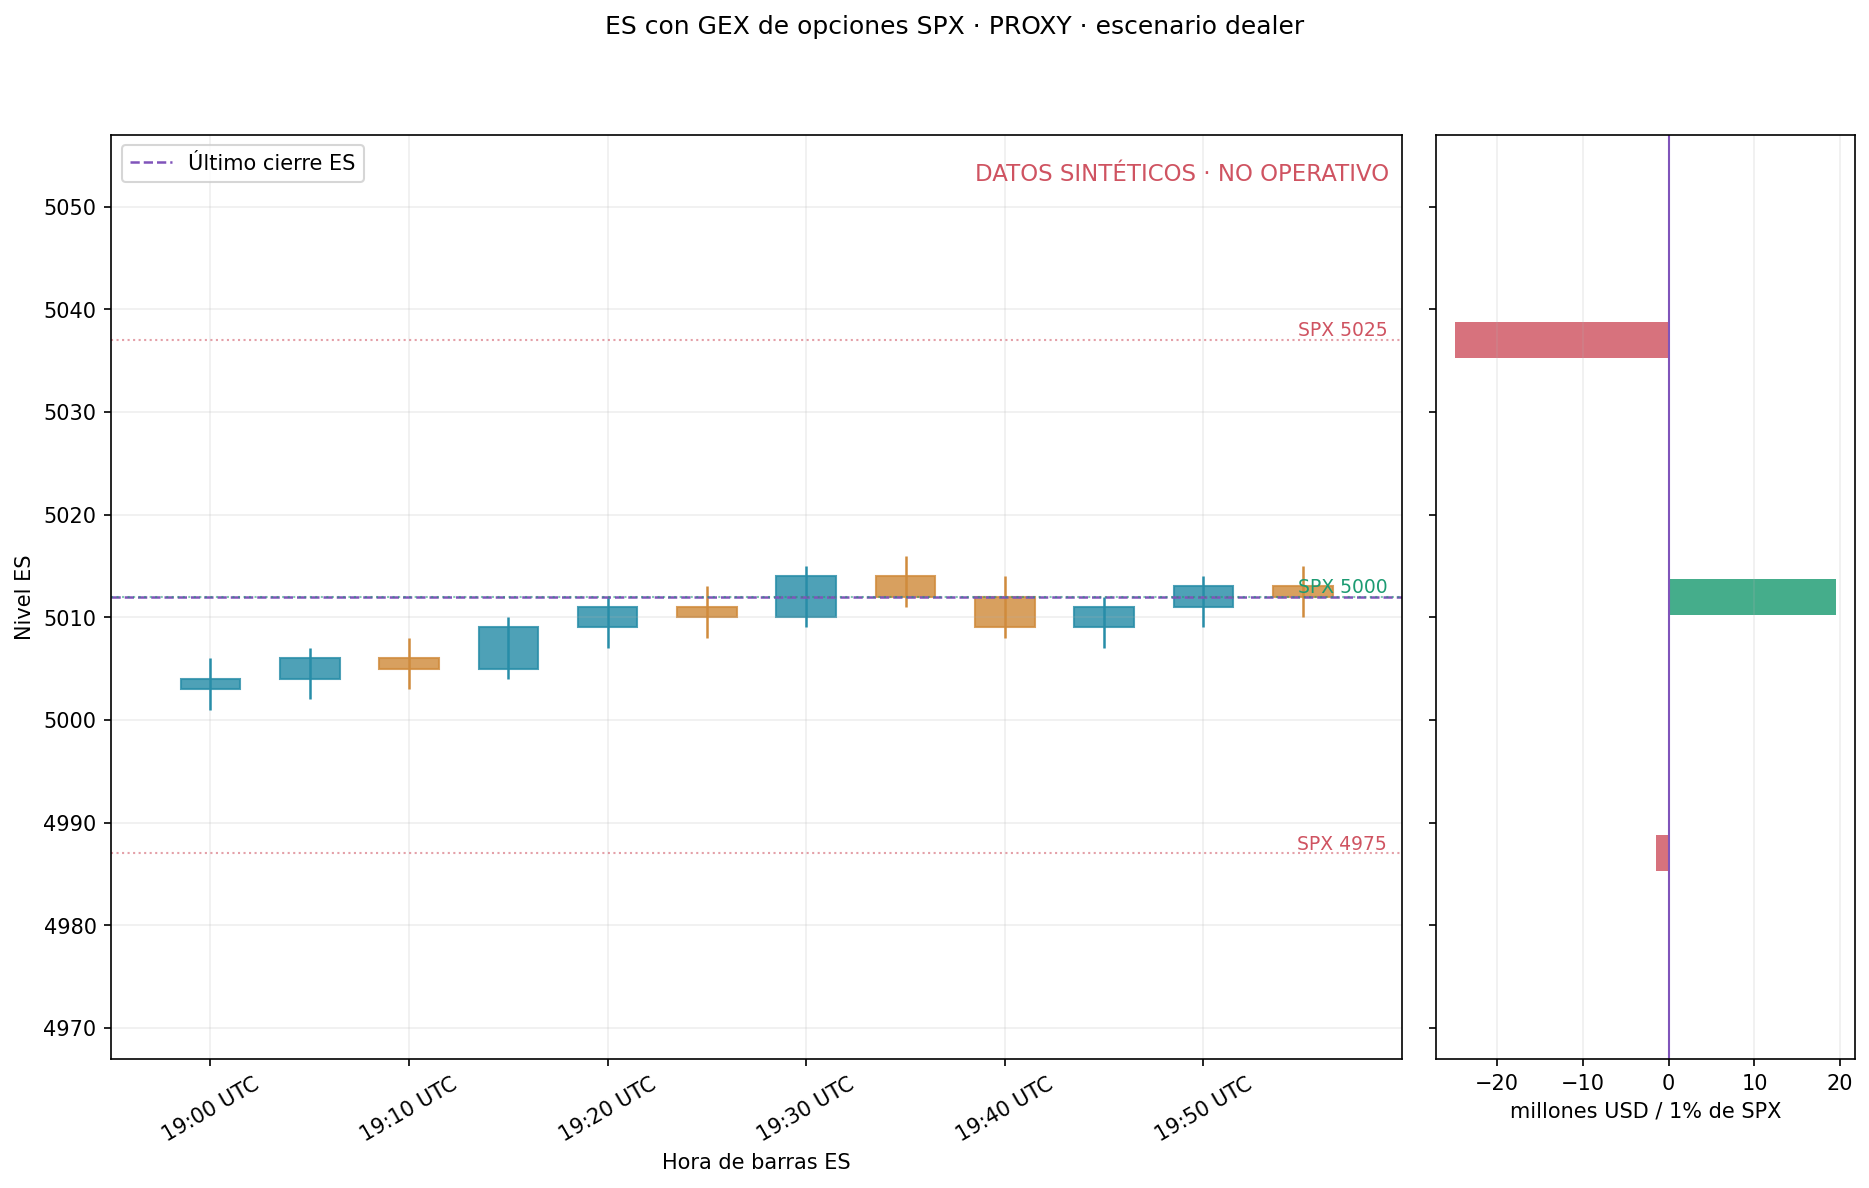

In [4]:
# GEX sobre el chart de ES: verde/rojo por signo del escenario dealer.
if "GEX" in GRAFICOS:
    dibujar_estudio("GEX")

C:\Users\Administrator\AppData\Local\Temp\ipykernel_7812\585979936.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.95), pad=1.7)


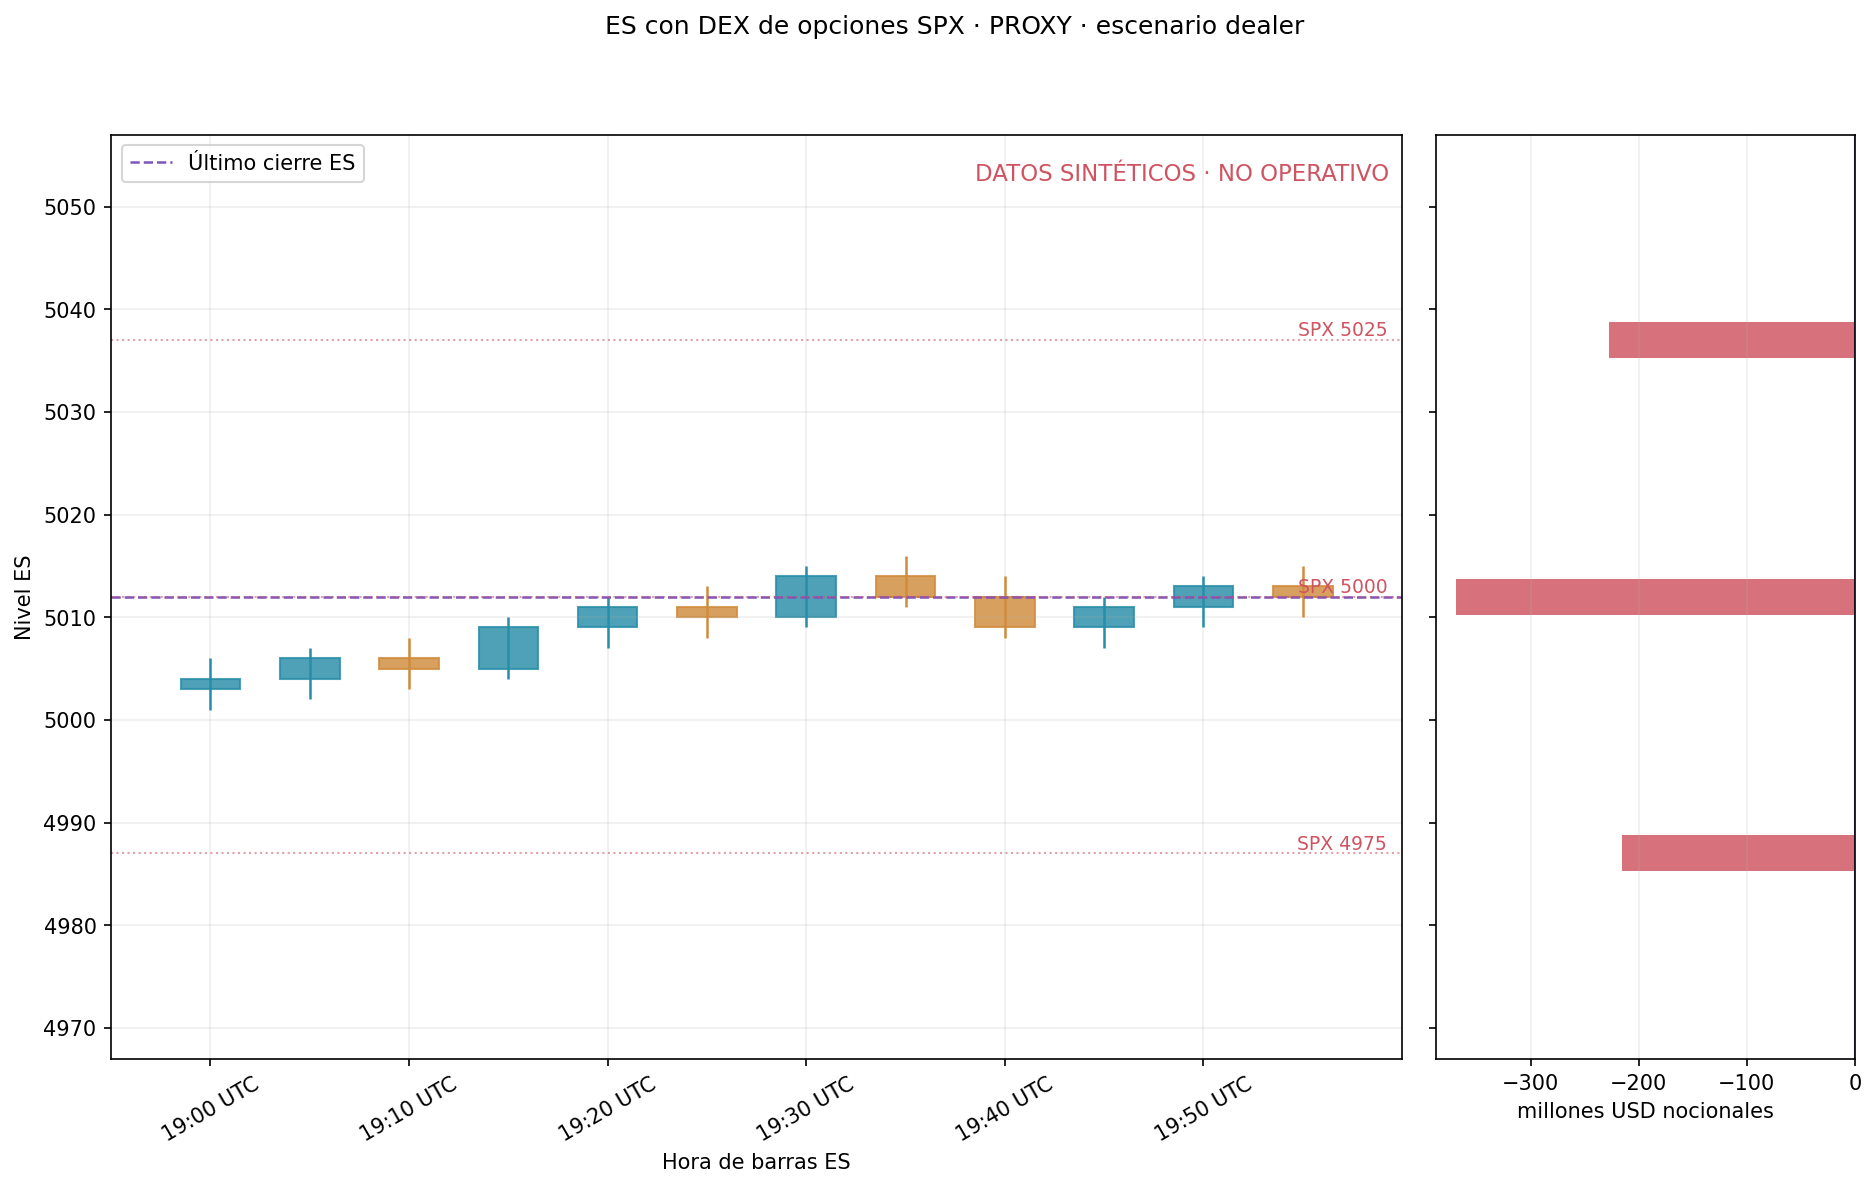

In [5]:
# DEX sobre el mismo chart de ES; no se fuerza un signo para crear barras verdes.
if "DEX" in GRAFICOS:
    dibujar_estudio("DEX")